In [15]:
# Prepare environment
from pathlib import Path
import pandas as pd
import geopandas as gpd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Set file paths
root_fldr = Path.cwd().parent
raw_fldr = root_fldr/"data"/"raw"
processed_fldr = root_fldr/'data'/'processed'
prescribed_burns_cleaned = gpd.read_file(processed_fldr / "prescribed_burns.gpkg")
calflora_full = gpd.read_file(processed_fldr / "calflora_full_cleaned.gpkg")

In [16]:
# Join invasive species and prescribed fire data together
fire_with_plants_joined = gpd.sjoin(
    left_df = calflora_full,
    right_df = prescribed_burns_cleaned,
    predicate = 'intersects',
    how = 'inner'
)

fire_with_plants_joined.info()

fire_with_plants_joined.head()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 2850 entries, 440 to 215178
Data columns (total 21 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   id                 2850 non-null   str           
 1   common_name        2849 non-null   str           
 2   scientific_name    2850 non-null   str           
 3   date               2850 non-null   datetime64[ms]
 4   number_of_plants   2726 non-null   str           
 5   latitude           2850 non-null   float64       
 6   longitude          2850 non-null   float64       
 7   year_left          2850 non-null   int64         
 8   geometry           2850 non-null   geometry      
 9   index_right        2850 non-null   int64         
 10  year_right         2850 non-null   int64         
 11  agency             2850 non-null   str           
 12  burn_name          2694 non-null   str           
 13  treatment_type     2842 non-null   float64       
 14  s

,id,common_name,scientific_name,date,number_of_plants,latitude,longitude,year_left,geometry,index_right,...,agency,burn_name,treatment_type,start_date,end_date,acres_treated,gis_acres_treated,Shape_Length,Shape_Area,duration_days
440,io200488,Stinkwort,Dittrichia graveolens,2026-10-15,46063,38.522141,-122.759431,2026,POINT (-240273.137 59720.681),223,...,OTH,2025 Treatment,1.0,2025-06-25,2025-06-25,5.62,5.615889,954.594358,22726.6956,0.0
441,io200494,Stinkwort,Dittrichia graveolens,2026-10-15,18568,38.522050,-122.759630,2026,POINT (-240290.754 59711.074),223,...,OTH,2025 Treatment,1.0,2025-06-25,2025-06-25,5.62,5.615889,954.594358,22726.6956,0.0
442,io200493,Stinkwort,Dittrichia graveolens,2026-10-15,46063,38.522700,-122.760150,2026,POINT (-240333.917 59784.616),223,...,OTH,2025 Treatment,1.0,2025-06-25,2025-06-25,5.62,5.615889,954.594358,22726.6956,0.0
443,io200490,Stinkwort,Dittrichia graveolens,2026-10-15,46063,38.522850,-122.760090,2026,POINT (-240328.209 59801.131),223,...,OTH,2025 Treatment,1.0,2025-06-25,2025-06-25,5.62,5.615889,954.594358,22726.6956,0.0
444,io200482,Stinkwort,Dittrichia graveolens,2026-10-15,51 - 100,38.522810,-122.760330,2026,POINT (-240349.23 59797.295),223,...,OTH,2025 Treatment,1.0,2025-06-25,2025-06-25,5.62,5.615889,954.594358,22726.6956,0.0


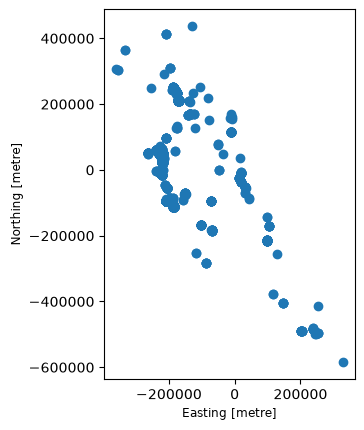

In [17]:
# Plot joined data
fire_with_plants_joined.plot();

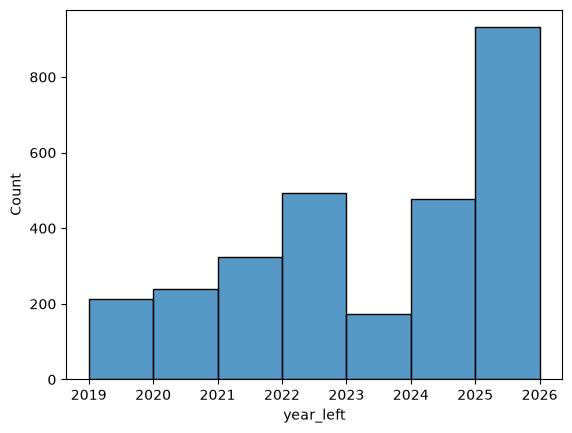

In [23]:
sns.histplot(data=fire_with_plants_joined, x="year_left", binwidth=1);

In [24]:
fire_with_plants_joined["before_after"] = np.select(
    [
        (fire_with_plants_joined["date"] < fire_with_plants_joined["start_date"]) &
        ((fire_with_plants_joined["start_date"] - fire_with_plants_joined["date"]).dt.days <= 365),
        (fire_with_plants_joined["date"] > fire_with_plants_joined["end_date"]) &
        ((fire_with_plants_joined["date"] - fire_with_plants_joined["end_date"]).dt.days <= 365),
        (fire_with_plants_joined["date"] > fire_with_plants_joined["start_date"]) &
        (fire_with_plants_joined["date"] < fire_with_plants_joined["end_date"])
    ],
    ["before", "after", "during"],
    default="neither"
)

In [25]:
fire_with_plants_joined["before_after"].value_counts()

before_after
neither    2146
after       591
before      113
Name: count, dtype: int64

In [ ]:
invasives_within_year = fire_with_plants_joined.loc[fire_with_plants_joined["before_after"] != "neither"]

In [28]:
invasives_within_year["before_after"].value_counts()

before_after
after     591
before    113
Name: count, dtype: int64

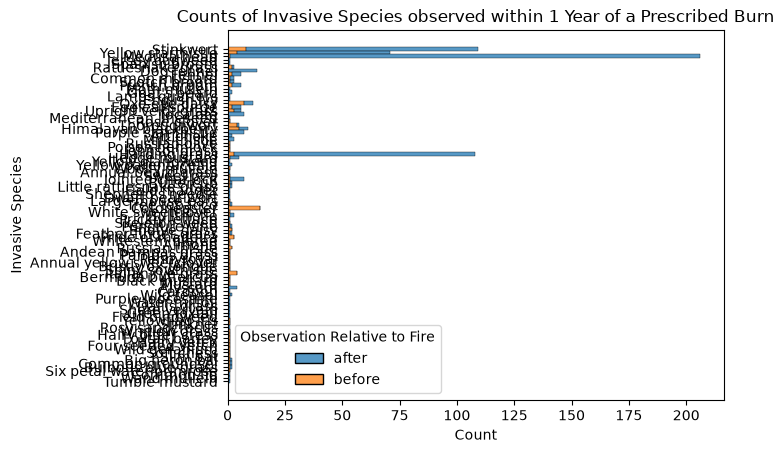

In [29]:
g = sns.histplot(data = invasives_within_year, y = "common_name", hue= "before_after", hue_order= ["after", "before"], multiple= "stack")

g.set(xlabel = "Count",
      ylabel = "Invasive Species",
      title = "Counts of Invasive Species observed within 1 Year of a Prescribed Burn"
              );
g.get_legend().set_title("Observation Relative to Fire")

In [31]:
invasives_table = invasives_within_year.loc[:, ["common_name", "before_after"]]

invasives_summary = invasives_table.groupby(["common_name", "before_after"]).size().reset_index(name="count")

invasives_summary_wide = (
    invasives_summary
    .pivot_table(
        index = "common_name",
        columns = "before_after",
        values = "count"
    )
    .fillna(0)
    .reset_index()
)

invasives_summary_wide = invasives_summary_wide[
    ["common_name", "before", "after"]
]


invasives_summary_wide_nice = (
    invasives_summary_wide
    .assign(
        Before = lambda df: df["before"].astype(int),
        After = lambda df: df["after"].astype(int)
    )
    .rename_axis(columns=None)
    .reset_index(drop=True)
)

In [35]:
invasives_summary_wide_nice.loc[
    invasives_summary_wide_nice["Before"] + invasives_summary_wide_nice["After"] > 2,
    ["common_name", "Before", "After"]
]

,common_name,Before,After
1,Alyssum,0,4
11,Bullthistle,1,2
16,Common mustard,1,2
17,Cotoneaster,14,0
19,Dog fennel,0,13
21,Eggleaf spurge,2,4
25,Fennel,2,4
30,French broom,2,4
35,Harding grass,3,105
36,Hedge mustard,1,4
